Already up to date.
Apni audio file select karo:


Saving sample.wav to sample (3).wav
Audio info: {'duration_sec': 37.35, 'sample_rate': 16000, 'num_samples': 597675, 'max_amplitude': 0.131}


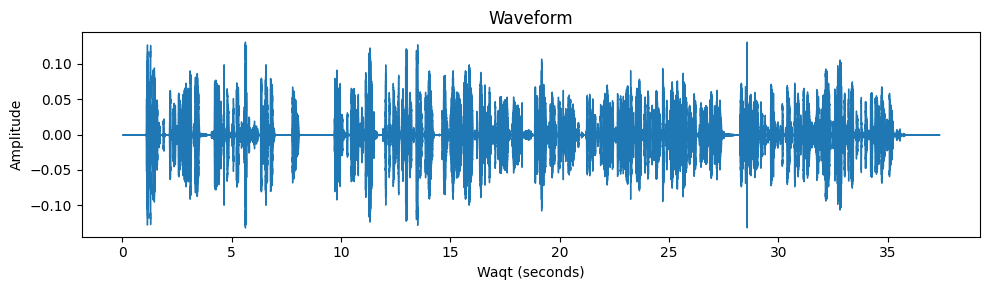

8000 Hz par awaaz:


4000 Hz par awaaz:


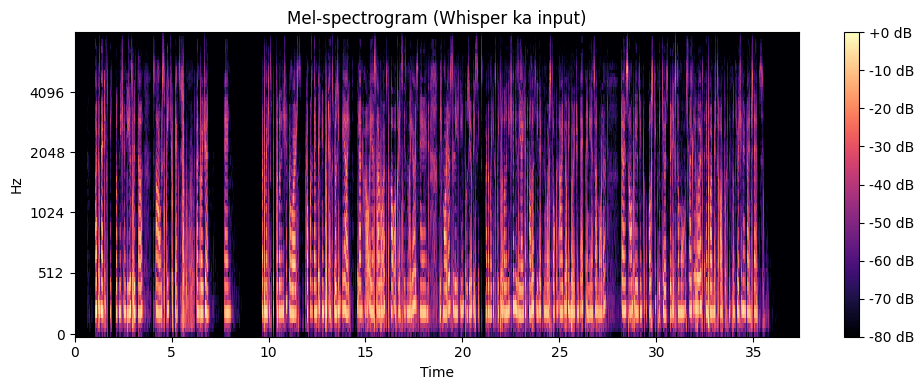

Mel shape: (80, 3736)


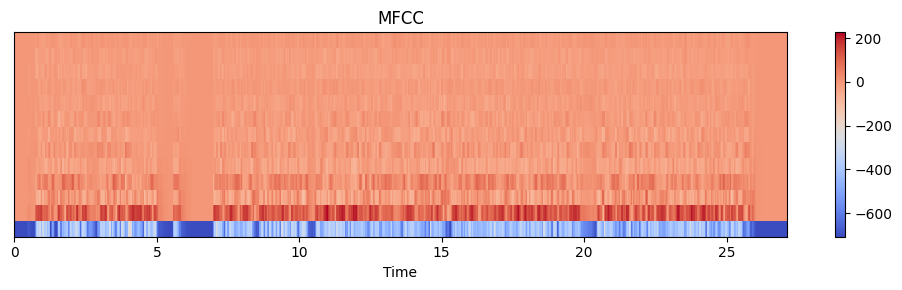

MFCC shape: (13, 1168)


In [13]:
# ---------- 1. Repo ka latest code lo ----------
import os, sys

REPO_URL = "https://github.com/FatimaaShaheen/urdu-asr-subtitles.git"
REPO_DIR = "/content/urdu-asr-subtitles"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !cd {REPO_DIR} && git pull

# ---------- 2. Libraries install ----------
!pip install -q librosa soundfile

# ---------- 3. Python ko 'src' ka path batao ----------
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.append(REPO_DIR)

# ---------- 4. Apne functions import ----------
from src.data.audio_utils import (
    load_audio, audio_info, mel_spectrogram, get_mfcc,
    plot_waveform, plot_mel, plot_mfcc,
)
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from google.colab import files

# ---------- 5. Audio upload ----------
print("Apni audio file select karo:")
uploaded = files.upload()
path = list(uploaded.keys())[0]

# ---------- 6. Load aur info ----------
y, sr = load_audio(path)
info = audio_info(y, sr)
print("Audio info:", info)
display(Audio(y, rate=sr))

# ---------- 7. Waveform ----------
plot_waveform(y, sr)
plt.show()

# ---------- 8. Sampling rate ka tajurba ----------
for new_sr in (8000, 4000):
    y_low = librosa.resample(y, orig_sr=sr, target_sr=new_sr)
    print(f"{new_sr} Hz par awaaz:")
    display(Audio(y_low, rate=new_sr))

# ---------- 9. Mel-spectrogram aur MFCC ----------
plot_mel(y, sr)
plt.show()
print("Mel shape:", mel_spectrogram(y, sr).shape)

plot_mfcc(y, sr)
plt.show()
print("MFCC shape:", get_mfcc(y, sr).shape)